<a href="https://colab.research.google.com/github/parthsingh22/UCS420P/blob/main/Assignment_7_Cognitive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170086         # <-- your full roll number
NAME = "Parth Singh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170086   Name: Parth Singh   Fingerprint: 0C06FFA8   Tickets: 13

Ticket_ID                                                                              Ticket_Text
      T01                I was locked out of the password after the latest update. This is urgent.
      T02              I couldn't connect to the Matlab during the lab. Is there another solution?
      T03                   VPN is not working when connected to campus Wi-Fi. Can you check this?
      T04 I was locked out of the Wi-Fi before the assignment deadline. I don't know what changed.
      T05                                                    I tried again... still no response!!!
      T06             I keep getting logged out of the VPN when I use mobile hotspot. Please help.
      T07                        I reinstalled the projector after the latest update. Please help.
      T08                              Laptop has stopped syncing since yesterday. This is urgent.
      T09                 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:

import pandas as pd

rows = []
processed = {}

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    processed[row["Ticket_ID"]] = result

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": summary["Sentences"].sum(),
    "Tokens": summary["Tokens"].sum(),
    "Punctuation Tokens": summary["Punctuation Tokens"].sum(),
    "Stopwords": summary["Stopwords"].sum(),
    "Unique Tokens": len(set(
        token
        for result in processed.values()
        for token in result["tokens"]
    )),
    "Final Tokens": summary["Final Tokens"].sum()
}

summary = pd.concat(
    [summary, pd.DataFrame([total_row])],
    ignore_index=True
)

display(summary)

#preprocessing details for one selected ticket
ticket_id = "T04"
result = processed[ticket_id]

print(f"\nPreprocessing details for {ticket_id}")
print("Tokens:", result["tokens"])
print("Punctuation tokens:", result["punct"])
print("Stopwords:", result["stops"])
print("Final tokens:", result["final"])


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,16,2,9,14,5
1,T02,2,16,2,7,15,7
2,T03,2,15,2,7,15,6
3,T04,2,19,2,10,16,7
4,T05,2,10,4,3,8,3
5,T06,2,17,2,6,15,9
6,T07,2,12,2,4,10,6
7,T08,2,11,2,3,10,6
8,T09,2,10,2,4,9,4
9,T10,2,15,2,6,14,7



Preprocessing details for T04
Tokens: ['i', 'was', 'locked', 'out', 'of', 'the', 'wi-fi', 'before', 'the', 'assignment', 'deadline', '.', 'i', 'do', "n't", 'know', 'what', 'changed', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['i', 'was', 'out', 'of', 'the', 'before', 'the', 'i', 'do', 'what']
Final tokens: ['locked', 'wi-fi', 'assignment', 'deadline', "n't", 'know', 'changed']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In my dataset, tokens such as 'n't' are not complete words. They come from contractions in the original tickets. For example, in T04, the sentence contains "I don't know what changed." The word_tokenize()' function splits "don't" into 'do' and 'n't'. Since 'do' is removed as a stopword but 'n't' remains, it appears in the final tokens. This shows that the preprocessing pipeline can leave behind parts of contractions instead of complete words.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [10]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re

# Combine the generated tickets with the provided test lines
all_texts = df["Ticket_Text"].tolist() + TEST_LINES

# 1. Extraction patterns
long_word_pattern = r"\b[A-Za-z]+(?:'[A-Za-z]+)*\b"
number_pattern = r"\b\d+(?:[.,]\d+)*\b"
capitalized_pattern = r"\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b|\b[A-Z]{2,}\b"
vowel_pattern = r"\b[aeiou][A-Za-z]*(?:'[A-Za-z]+)*\b"

for i, text in enumerate(all_texts, start=1):
    words = re.findall(long_word_pattern, text)
    long_words = [w for w in words if len(w.replace("'", "")) > 5]

    print(f"\nText {i}: {text}")
    print("Words longer than 5 letters:", long_words)
    print("Numbers:", re.findall(number_pattern, text))
    print("Capitalized words:", re.findall(capitalized_pattern, text))
    print(
        "Words starting with a vowel:",
        re.findall(vowel_pattern, text, flags=re.IGNORECASE)
    )

# 2. Replacement patterns
email_pattern = (
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)

url_pattern = r"https?://[^\s<>\"']+|www\.[^\s<>\"']+"

phone_pattern = (
    r"(?<!\w)(?:\+\d{1,3}[ -]?)?"
    r"(?:\d{5}[ -]\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)"
)

def clean_text(text):
    # Replace URLs while preserving trailing punctuation
    def replace_url(match):
        url = match.group()
        cleaned_url = url.rstrip(".,;!?")
        trailing_punctuation = url[len(cleaned_url):]
        return "<URL>" + trailing_punctuation

    text = re.sub(url_pattern, replace_url, text)
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)

    return text

# 3. Display replacement results
print("\n\nREPLACEMENT RESULTS")

for i, text in enumerate(all_texts, start=1):
    print(f"{i}: {clean_text(text)}")



Text 1: I was locked out of the password after the latest update. This is urgent.
Words longer than 5 letters: ['locked', 'password', 'latest', 'update', 'urgent']
Numbers: []
Capitalized words: ['I', 'This']
Words starting with a vowel: ['I', 'out', 'of', 'after', 'update', 'is', 'urgent']

Text 2: I couldn't connect to the Matlab during the lab. Is there another solution?
Words longer than 5 letters: ["couldn't", 'connect', 'Matlab', 'during', 'another', 'solution']
Numbers: []
Capitalized words: ['I', 'Matlab', 'Is']
Words starting with a vowel: ['I', 'Is', 'another']

Text 3: VPN is not working when connected to campus Wi-Fi. Can you check this?
Words longer than 5 letters: ['working', 'connected', 'campus']
Numbers: []
Capitalized words: ['VPN', 'Wi-Fi', 'Can']
Words starting with a vowel: ['is']

Text 4: I was locked out of the Wi-Fi before the assignment deadline. I don't know what changed.
Words longer than 5 letters: ['locked', 'before', 'assignment', 'deadline', 'changed']
N

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*In my dataset, some words are capitalized only because they appear at the beginning of a sentence. For example, "This", "Please", and "The" are capitalized in this way. However, terms like "VPN" and "Wi-Fi" are capitalized because they are technical terms or acronyms. Therefore, regular expressions can identify capitalized words, but the context is needed to determine whether capitalization is due to sentence position or the word itself.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://[^\s<>\[\]()\"']+|www\.[^\s<>\[\]()\"']+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d{1,3}[ -]?(?:\d{5}[ -]\d{5}|\d{4}-\d{3}-\d{4}|\d{3}-\d{3}-\d{4})|\d+(?:[.,]\d+)+(?:%)?|\d+(?:,\d{3})*(?:\.\d+)?%?|[A-Za-z]+(?:-[A-Za-z]+)+|[A-Za-z]+(?:['’][A-Za-z]+)?|\.{3}|[^\w\s]"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    text = re.sub(
        r"\[([^\]]+)\]\([^)]+\)",
        r"\1",
        text
    )
    return tokenizer.tokenize(text)

print("CUSTOM TOKENIZER ON TEST_LINES")

for i, text in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}: {text}")
    print("my_tokenize:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))

print("\nCOMPARISON ON GENERATED TICKETS")

different_tickets = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    standard_tokens = word_tokenize(text)

    if custom_tokens != standard_tokens:
        different_tickets.append(ticket_id)
        print(f"\n{ticket_id}:")
        print("my_tokenize:", custom_tokens)
        print("word_tokenize:", standard_tokens)

print("\nNumber of tickets tokenized differently:",
      len(different_tickets), "out of", len(df))
print("Different ticket IDs:", different_tickets)


CUSTOM TOKENIZER ON TEST_LINES

Test line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test line 3: The state-of-the-art lab isn't open;

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex_stemmer = RegexpStemmer(r'(ing|ed|ly|s)$')
lemmatizer = WordNetLemmatizer()

unique_final_tokens = sorted(set(
    token
    for result in processed.values()
    for token in result["final"]
))

tagged_words = pos_tag(unique_final_tokens)

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('N'):
        return 'n'
    elif tag.startswith('R'):
        return 'r'
    else:
        return 'n'

rows = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    rows.append({
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regex_stemmer.stem(word),
        "Lemmatizer": lemmatizer.lemmatize(word, pos)
    })

comparison_df = pd.DataFrame(rows)

different_words = comparison_df[
    comparison_df.iloc[:, 1:].nunique(axis=1) > 1
]

display(different_words.reset_index(drop=True))

,Word,Porter,Lancaster,Regexp,Lemmatizer
0,'s,'s,'s,','s
1,another,anoth,anoth,another,another
2,assignment,assign,assign,assignment,assignment
3,campus,campu,camp,campu,campus
4,changed,chang,chang,chang,change
5,crashes,crash,crash,crashe,crash
6,deadline,deadlin,deadlin,deadline,deadline
7,getting,get,get,gett,get
8,latest,latest,latest,latest,late
9,logged,log,log,logg,log


**Observe:** Give one over-stemming and one under-stemming example from your table.

Over-stemming occurs when a stemmer removes too much of a word and produces an unnecessarily shortened stem. Lancaster Stemmer is more aggressive, so it may sometimes reduce words more than expected.

Under-stemming occurs when related words are not reduced to the same root. Different stemming methods may leave some variations of a word in different forms. This shows that stemming is not always perfect, and the result depends on the algorithm used.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,168,87,0.5179
1,S2,140,80,0.5714
2,S3,73,53,0.7260
3,S4,73,52,0.7123



Top 10 Words of S1:
[('.', 19), ('the', 12), ('i', 9), ('is', 5), ('out', 3), ('of', 3), ('this', 3), ("n't", 3), ('to', 3), ('not', 3)]

Top 10 Words of S3:
[("n't", 3), ('please', 3), ('projector', 3), ('laptop', 3), ('locked', 2), ('latest', 2), ('update', 2), ('urgent', 2), ('vpn', 2), ('working', 2)]


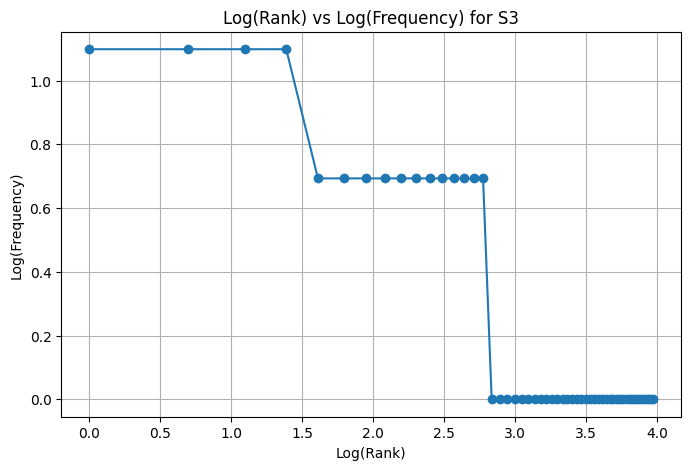


Top 5 Bigrams of S1:
[(('.', 'i'), 5), (('out', 'of'), 3), (('of', 'the'), 3), (('.', 'please'), 3), (('i', 'was'), 2)]

Top 5 Bigrams of S3:
[(('latest', 'update'), 2), (("n't", 'know'), 2), (('know', 'changed'), 2), (('please', 'help'), 2), (('locked', 'password'), 1)]


In [9]:
from collections import Counter
from nltk.util import ngrams
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.stem import PorterStemmer

porter = PorterStemmer()

# S1: All tokens
S1 = [
    token
    for result in processed.values()
    for token in result["tokens"]
]

# S2: Tokens without punctuation
S2 = [
    token
    for result in processed.values()
    for token in result["tokens"]
    if token not in result["punct"]
]

# S3: Final tokens
S3 = [
    token
    for result in processed.values()
    for token in result["final"]
]

# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]


# Corpus statistics
def corpus_stats(name, corpus):
    total_tokens = len(corpus)
    unique_tokens = len(set(corpus))
    ttr = unique_tokens / total_tokens if total_tokens else 0

    return {
        "Corpus": name,
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    }


stats = pd.DataFrame([
    corpus_stats("S1", S1),
    corpus_stats("S2", S2),
    corpus_stats("S3", S3),
    corpus_stats("S4", S4)
])

print("CORPUS STATISTICS")
display(stats)


# Top 10 words of S1
print("\nTop 10 Words of S1:")
print(Counter(S1).most_common(10))


# Top 10 words of S3
print("\nTop 10 Words of S3:")
print(Counter(S3).most_common(10))


# Log(rank) vs Log(frequency) plot for S3
frequency = Counter(S3)
sorted_frequency = sorted(frequency.values(), reverse=True)

rank = np.arange(1, len(sorted_frequency) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(rank), np.log(sorted_frequency), marker='o')
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()


# Top 5 bigrams of S1
bigrams_S1 = Counter(ngrams(S1, 2))

print("\nTop 5 Bigrams of S1:")
print(bigrams_S1.most_common(5))


# Top 5 bigrams of S3
bigrams_S3 = Counter(ngrams(S3, 2))

print("\nTop 5 Bigrams of S3:")
print(bigrams_S3.most_common(5))

6. Interpretation
Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?
(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
(c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

(a) Why does TTR change from S1 to S4 in your dataset?

TTR changes because each preprocessing step modifies the text by removing unnecessary elements and reducing different word forms to a common form. As punctuation, stopwords, and word variations are removed, the number of unique words changes relative to the total number of tokens. This affects the TTR value at each stage.

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

For example, an email address such as it.helpdesk@thapar.edu is treated as a single token by our custom tokenizer because we specifically included a pattern for email addresses. However, word_tokenize() may split it into multiple tokens. This is because our tokenizer is designed to recognize special patterns like emails, URLs, phone numbers, decimals, and hyphenated words.

(c) Give one example where stemming produces an undesirable result.

Stemming can sometimes produce words that are not proper English words. For example, the Porter Stemmer may convert studies into studi. This happens because stemming removes word endings based on rules rather than checking whether the resulting word is meaningful.

(d) Give an example where POS-aware lemmatization preserves meaning better than stemming.

For example, better can be converted to good by lemmatization when it is identified as an adjective. Unlike stemming, lemmatization considers the grammatical role of a word and returns its meaningful base form, which helps preserve the original meaning.